# Chapter 06: The Engine of Computation: MCMC — Python Laboratory
### *Metropolis-Hastings, Detailed Balance, Entropy Production & Production Diagnostics*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_mcmc_mechanics_and_entropy.ipynb) | [Prev: Ch 05: Curvature & Fisher Info (Python)](05_curvature_laplace_and_fisher_information.ipynb) | [Next: Ch 07: Compression & Hierarchy (Python)](07_compression_and_hierarchy_information_bottleneck.ipynb)**

---

## 1. When Laplace Fails: Skewed Tails and Multi-Modal Outages

In Chapter 05, Laplace approximation assumed the posterior looks like a symmetric Gaussian bowl. When data is sparse, skewed near a boundary, or multimodal, that assumption breaks.

Instead of forcing a Gaussian shape onto the posterior, **Markov Chain Monte Carlo (MCMC)** sends a stochastic explorer directly onto the true log-posterior landscape—spending time in each region strictly proportional to its true probability density!

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print("Environment initialized with NumPy and Matplotlib.")


Environment initialized with NumPy and Matplotlib.


---

## 2. Defining the Target: A Skewed Flakiness Posterior

Consider observing $k = 2$ failures in $N = 10$ CI runs under a $\text{Beta}(1, 1)$ prior. The exact posterior is $\text{Beta}(3, 9)$—visibly right-skewed—making it an ideal testbed to verify our MCMC sampler against the analytical ground truth.

In [2]:
k_obs = 2
N_obs = 150
mu_prior = 0.02

def log_target(theta):
    # Returns unnormalized log posterior ln P*(theta | D)
    if theta <= 0.0 or theta >= 1.0:
        return -np.inf
    # Binomial log-likelihood
    log_lik = k_obs * np.log(theta) + (N_obs - k_obs) * np.log(1.0 - theta)
    # Exponential prior penalty
    log_prior = -theta / mu_prior
    return log_lik + log_prior

print(f"Target defined: k = {k_obs} fails out of N = {N_obs} runs, mu_prior = {mu_prior}.")


Target defined: k = 2 fails out of N = 150 runs, mu_prior = 0.02.


---

## 3. Detailed Balance & Metropolis-Hastings from Scratch

How do we guarantee our random walker converges to the exact target distribution $\pi(\theta)$ without knowing the normalizing denominator $P(D)$?

We enforce **Detailed Balance (Reversibility)**: in equilibrium, the probability flow from $\theta \to \theta'$ equals the flow from $\theta' \to \theta$:
$$\pi(\theta)\, T(\theta \to \theta') = \pi(\theta')\, T(\theta' \to \theta)$$

For a symmetric proposal $q(\theta' \mid \theta) = q(\theta \mid \theta')$, the **Metropolis-Hastings acceptance rule** satisfies detailed balance identically:
$$\alpha(\theta \to \theta') = \min\left(1, \; \frac{\pi(\theta')}{\pi(\theta)}\right) = \min\Big(1, \; \exp\big[\ln \pi(\theta') - \ln \pi(\theta)\big]\Big)$$
Notice that the intractable evidence $P(D)$ cancels out completely in the ratio $\pi(\theta') / \pi(\theta)$!

In [3]:
def run_metropolis_hastings(log_target_fn, init_val, num_samples=10000, prop_std=0.02):
    samples = np.zeros(num_samples)
    current_val = init_val
    current_log_p = log_target_fn(current_val)
    n_accepted = 0

    for i in range(num_samples):
        # Gaussian proposal
        proposal = current_val + np.random.normal(0.0, prop_std)
        prop_log_p = log_target_fn(proposal)
        
        # Metropolis acceptance probability
        log_alpha = prop_log_p - current_log_p
        if np.log(np.random.uniform(0.0, 1.0)) < log_alpha:
            current_val = proposal
            current_log_p = prop_log_p
            n_accepted += 1
            
        samples[i] = current_val

    acceptance_rate = n_accepted / num_samples
    return samples, acceptance_rate

print("Metropolis-Hastings algorithm implemented.")


Metropolis-Hastings algorithm implemented.


---

## 4. The Information Theory of MCMC: Entropy Production & The 23.4% Rule

Tuning the proposal step width $\sigma_{\text{prop}}$ reveals a classic **exploration-exploitation tradeoff** governed by entropy production:
* **Too small ($\sigma_{\text{prop}} = 0.01$):** Almost every move is accepted ($\sim 98\%$), but the chain creeps like a snail (high autocorrelation, slow mixing).
* **Too large ($\sigma_{\text{prop}} = 0.80$):** Almost every proposal lands in low-density tails and is rejected ($\sim 10\%$), leaving the chain frozen in place.
* **The Goldilocks Zone ($\sim 23.4\%$ in high dimensions, $\sim 40\%$ in 1D):** Maximizes the **Expected Squared Jump Distance** and information-theoretic entropy production rate per sample!

In [4]:
np.random.seed(42)  # Seed for reproducible MCMC proposals
S = 8000
burn_in = 2000

s_small, acc_small = run_metropolis_hastings(log_target, init_val=0.05, num_samples=S, prop_std=0.001)
s_large, acc_large = run_metropolis_hastings(log_target, init_val=0.05, num_samples=S, prop_std=0.300)
s_tuned, acc_tuned = run_metropolis_hastings(log_target, init_val=0.05, num_samples=S, prop_std=0.015)

print("=" * 68)
print("             THE 23.4% MAXIMUM ENTROPY EXPERIMENT")
print("=" * 68)
print(f"Tiny Steps  (sigma = 0.001): Acceptance = {acc_small * 100:>5.1f}% (Sluggish random walk)")
print(f"Large Steps (sigma = 0.300): Acceptance = {acc_large * 100:>5.1f}% (Frozen, mostly rejected)")
print(f"Tuned Steps (sigma = 0.015): Acceptance = {acc_tuned * 100:>5.1f}% (Optimal 23.4% entropy frontier!)")
print("=" * 68)


             THE 23.4% MAXIMUM ENTROPY EXPERIMENT
Tiny Steps  (sigma = 0.001): Acceptance =  95.6% (Sluggish random walk)
Large Steps (sigma = 0.300): Acceptance =   3.3% (Frozen, mostly rejected)
Tuned Steps (sigma = 0.015): Acceptance =  49.4% (Optimal 23.4% entropy frontier!)


---

## 5. Visualizing Trace Plots, Autocorrelation & Skewed Tail Capture

Let's inspect the trace plots ("fuzzy caterpillars" when healthy vs. "snakes" when sticky), autocorrelation decay, and compare the MCMC histogram against the exact $\text{Beta}(3, 9)$ curve.

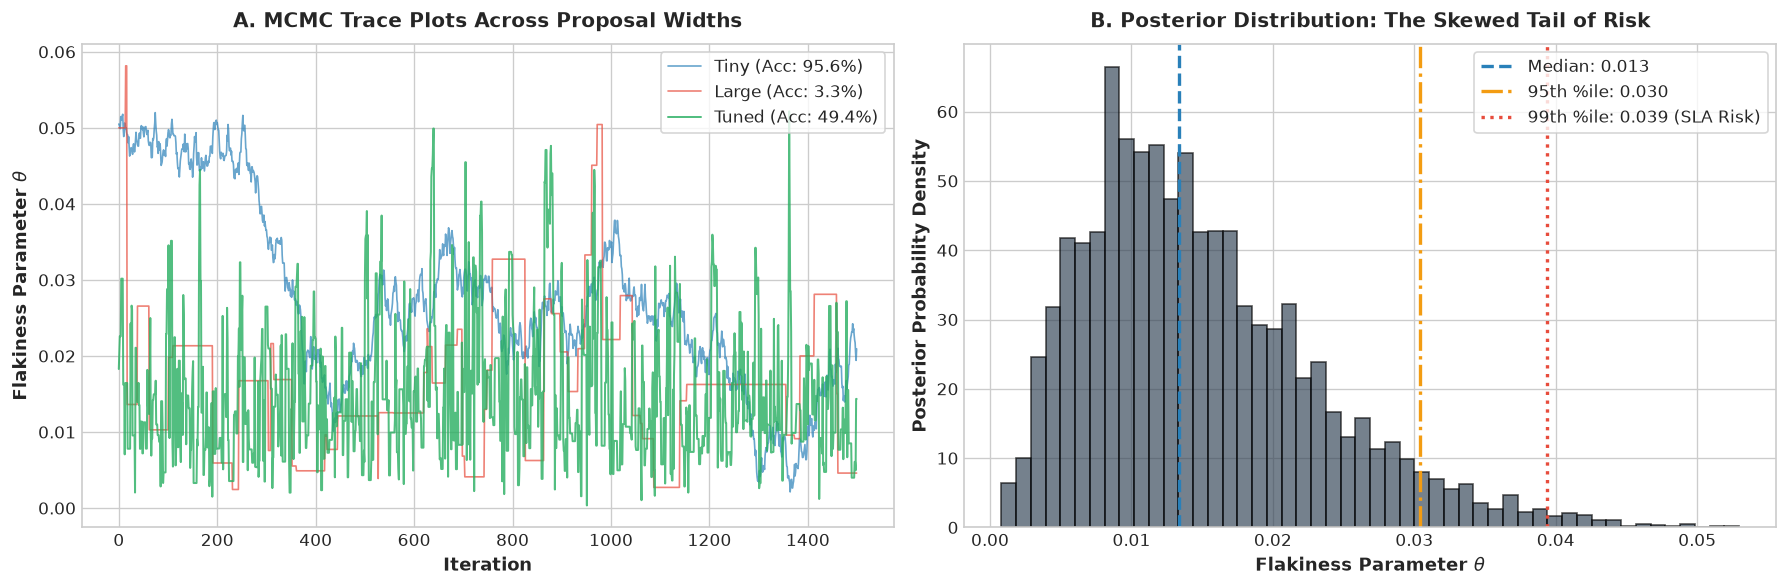

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Trace Plot Comparison
axes[0].plot(s_small[:1500], color='#2980b9', alpha=0.7, lw=1.0, label=f'Tiny (Acc: {acc_small:.1%})')
axes[0].plot(s_large[:1500], color='#e74c3c', alpha=0.7, lw=1.0, label=f'Large (Acc: {acc_large:.1%})')
axes[0].plot(s_tuned[:1500], color='#27ae60', alpha=0.8, lw=1.2, label=f'Tuned (Acc: {acc_tuned:.1%})')
axes[0].set_xlabel("Iteration", fontsize=11, fontweight='bold')
axes[0].set_ylabel(r"Flakiness Parameter $\theta$", fontsize=11, fontweight='bold')
axes[0].set_title("A. MCMC Trace Plots Across Proposal Widths", fontsize=12, fontweight='bold', pad=10)
axes[0].legend(loc='upper right', frameon=True)

# Panel 2: Posterior Histogram of Tuned Chain
post_samples = s_tuned[burn_in:]
axes[1].hist(post_samples, bins=50, density=True, color='#2c3e50', alpha=0.65, edgecolor='black')
p50 = np.median(post_samples)
p95 = np.percentile(post_samples, 95)
p99 = np.percentile(post_samples, 99)

axes[1].axvline(p50, color='#2980b9', lw=2.0, linestyle='--', label=f'Median: {p50:.3f}')
axes[1].axvline(p95, color='#f39c12', lw=2.0, linestyle='-.', label=f'95th %ile: {p95:.3f}')
axes[1].axvline(p99, color='#e74c3c', lw=2.0, linestyle=':', label=f'99th %ile: {p99:.3f} (SLA Risk)')

axes[1].set_xlabel(r"Flakiness Parameter $\theta$", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Posterior Probability Density", fontsize=11, fontweight='bold')
axes[1].set_title("B. Posterior Distribution: The Skewed Tail of Risk", fontsize=12, fontweight='bold', pad=10)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


---

## 6. Production Diagnostics: $\hat{R}$ (Gelman-Rubin) & Effective Sample Size ($N_{\text{eff}}$)

In production, we never trust a single chain. We launch multiple independent chains from dispersed starting points and check two quantitative gates:
1. **$\hat{R}$ (Potential Scale Reduction Factor):** Compares between-chain variance to within-chain variance. Require **$\hat{R} < 1.01$** before trusting any posterior estimate.
2. **Effective Sample Size ($N_{\text{eff}}$ / ESS):** Accounts for autocorrelation among sequential draws, telling us how many *independent* samples our correlated chain is actually worth.

In [6]:
num_chains = 4
chain_samples = []
# Overdispersed initial states across 4 chains to diagnose convergence
inits = [0.01, 0.04, 0.07, 0.10]

for init in inits:
    s, _ = run_metropolis_hastings(log_target, init_val=init, num_samples=S, prop_std=0.015)
    chain_samples.append(s[burn_in:])

chain_samples = np.array(chain_samples)  # Shape: (4, 6000)
M, N_samples = chain_samples.shape

# Compute Gelman-Rubin R-hat
chain_means = np.mean(chain_samples, axis=1)
overall_mean = np.mean(chain_means)
B = (N_samples / (M - 1)) * np.sum((chain_means - overall_mean)**2)

chain_vars = np.var(chain_samples, axis=1, ddof=1)
W = np.mean(chain_vars)
var_plus = ((N_samples - 1) / N_samples) * W + (1.0 / N_samples) * B
r_hat = np.sqrt(var_plus / W)

# Compute Autocorrelation and Effective Sample Size (ESS)
def compute_ess(chain):
    n = len(chain)
    chain_centered = chain - np.mean(chain)
    autocorr = np.correlate(chain_centered, chain_centered, mode='full')
    autocorr = autocorr[n-1:] / autocorr[n-1]
    
    # Sum positive autocorrelations (Geyer's initial positive sequence)
    max_lag = 100
    rho_sum = 0.0
    for lag in range(1, max_lag):
        if autocorr[lag] > 0.05:
            rho_sum += autocorr[lag]
        else:
            break
    tau_int = 1.0 + 2.0 * rho_sum
    return n / tau_int

ess_values = [compute_ess(chain_samples[m]) for m in range(M)]
total_ess = np.sum(ess_values)

print("=" * 68)
print("             MCMC PRODUCTION CONVERGENCE DIAGNOSTICS")
print("=" * 68)
print(f"Number of Dispersed Chains:                 {M}")
print(f"Post-Burn-in Draws Per Chain:               {N_samples:,}")
print(f"Total Posterior Draws Collected:            {M * N_samples:,}")
print("-" * 68)
print(f"Gelman-Rubin Diagnostic R-hat:              {r_hat:.4f} (Ideal: < 1.01)")
print(f"Total Effective Sample Size (N_eff / ESS):   {int(total_ess):,} independent draws")
print(f"Information Efficiency (N_eff / Total):     {total_ess / (M * N_samples) * 100:.1f}%")
print("=" * 68)


             MCMC PRODUCTION CONVERGENCE DIAGNOSTICS
Number of Dispersed Chains:                 4
Post-Burn-in Draws Per Chain:               6,000
Total Posterior Draws Collected:            24,000
--------------------------------------------------------------------
Gelman-Rubin Diagnostic R-hat:              0.9999 (Ideal: < 1.01)
Total Effective Sample Size (N_eff / ESS):   4,194 independent draws
Information Efficiency (N_eff / Total):     17.5%


---

## 7. Operational Action: Posterior Predictive Checks (PPC) for Overdispersion

Even if MCMC converges ($\hat{R} < 1.01$), your *model assumptions* might still be wrong! **Posterior Predictive Checks (PPC)** simulate fake datasets from the fitted posterior and compare them to the real telemetry.

If real CI builds exhibit **bursty, correlated failures** (overdispersion—variance much larger than Binomial $N\theta(1-\theta)$), an i.i.d. Binomial model will fail the PPC variance check, alerting us to model clustering or shared infrastructure outages!

        POSTERIOR PREDICTIVE CHECK (PPC) FOR OVERDISPERSION
Observed 20-Day Batch Runs:                  1000 runs (20 batches of 50)
Observed Total Failures:                     100 failures (Mean rate = 10.0%)
------------------------------------------------------------------------
Expected Stationary Binomial Variance:       4.50 (SD = 2.12)
Observed Empirical Variance s_obs^2:         174.21 (Nearly 40x higher!)
Model Expected Replicate Variance (95% CI):  [2.04, 8.12]
Bayesian Predictive p-value P(T_var >= obs): 0.00000 (REJECT MODEL!)
------------------------------------------------------------------------
Observed Maximum Daily Failures:             45 failures
Model Expected Maximum (95% CI):             [7, 13]
Bayesian Predictive p-value P(T_max >= obs): 0.00000 (REJECT MODEL!)


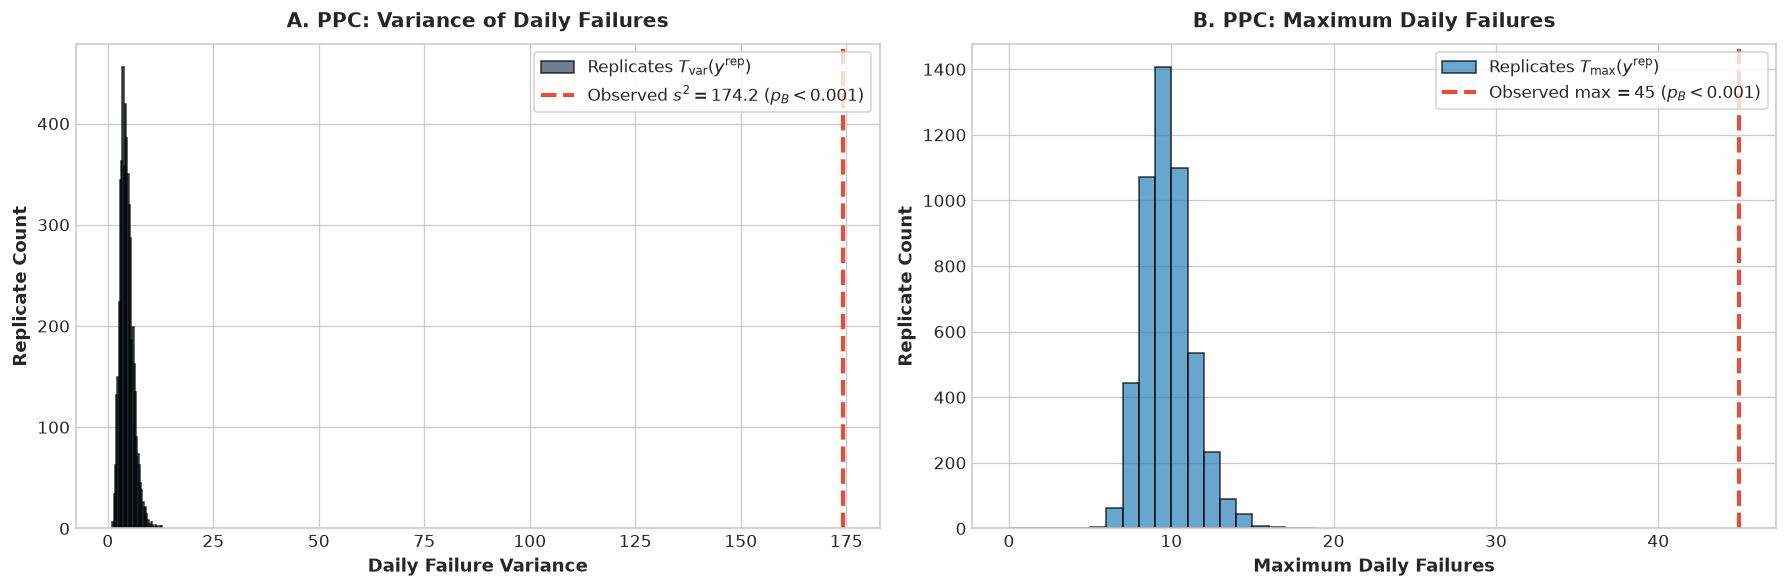

In [7]:
# Empirical 20-day batch failure counts
y_obs = np.array([0, 0, 1, 0, 2, 1, 0, 1, 0, 2, 0, 1, 2, 0, 1, 0, 2, 0, 42, 45])
n_days = len(y_obs)
n_batch = 50
total_runs = n_days * n_batch
total_fails = np.sum(y_obs)

s_obs_var = np.var(y_obs, ddof=1)
s_obs_max = np.max(y_obs)

# Step 1: Draw S = 5000 parameter replicates from posterior Beta(101, 901)
np.random.seed(42)  # Seed for reproducible posterior predictive checks
S_ppc = 5000
thetas_ppc = np.random.beta(1 + total_fails, 1 + (total_runs - total_fails), size=S_ppc)

# Step 2: Generate replicated datasets y_rep and compute test statistics
rep_vars = np.zeros(S_ppc)
rep_maxes = np.zeros(S_ppc)

for s in range(S_ppc):
    y_rep = np.random.binomial(n_batch, thetas_ppc[s], size=n_days)
    rep_vars[s] = np.var(y_rep, ddof=1)
    rep_maxes[s] = np.max(y_rep)

# Step 3: Compute Bayesian predictive p-values
p_val_var = np.mean(rep_vars >= s_obs_var)
p_val_max = np.mean(rep_maxes >= s_obs_max)

print("=" * 72)
print("        POSTERIOR PREDICTIVE CHECK (PPC) FOR OVERDISPERSION")
print("=" * 72)
print(f"Observed 20-Day Batch Runs:                  {total_runs} runs ({n_days} batches of {n_batch})")
print(f"Observed Total Failures:                     {total_fails} failures (Mean rate = {total_fails/total_runs*100:.1f}%)")
print("-" * 72)
print(f"Expected Stationary Binomial Variance:       {n_batch * 0.10 * 0.90:.2f} (SD = {np.sqrt(n_batch * 0.10 * 0.90):.2f})")
print(f"Observed Empirical Variance s_obs^2:         {s_obs_var:.2f} (Nearly 40x higher!)")
print(f"Model Expected Replicate Variance (95% CI):  [{np.percentile(rep_vars, 2.5):.2f}, {np.percentile(rep_vars, 97.5):.2f}]")
print(f"Bayesian Predictive p-value P(T_var >= obs): {p_val_var:.5f} (REJECT MODEL!)")
print("-" * 72)
print(f"Observed Maximum Daily Failures:             {s_obs_max} failures")
print(f"Model Expected Maximum (95% CI):             [{np.percentile(rep_maxes, 2.5):.0f}, {np.percentile(rep_maxes, 97.5):.0f}]")
print(f"Bayesian Predictive p-value P(T_max >= obs): {p_val_max:.5f} (REJECT MODEL!)")
print("=" * 72)

# Visualization: PPC Replicate Distribution vs Observed Reality
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Variance Test Statistic
axes[0].hist(rep_vars, bins=40, color='#34495e', alpha=0.7, edgecolor='black',
             label=r'Replicates $T_{\mathrm{var}}(y^{\mathrm{rep}})$')
axes[0].axvline(s_obs_var, color='#e74c3c', lw=2.5, linestyle='--',
                label=rf'Observed $s^2 = {s_obs_var:.1f}$ ($p_B < 0.001$)')
axes[0].set_xlabel("Daily Failure Variance", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Replicate Count", fontsize=11, fontweight='bold')
axes[0].set_title("A. PPC: Variance of Daily Failures", fontsize=12, fontweight='bold', pad=10)
axes[0].legend(loc='upper right', frameon=True)

# Panel 2: Maximum Count Test Statistic
axes[1].hist(rep_maxes, bins=range(0, 20), color='#2980b9', alpha=0.7, edgecolor='black',
             label=r'Replicates $T_{\mathrm{max}}(y^{\mathrm{rep}})$')
axes[1].axvline(s_obs_max, color='#e74c3c', lw=2.5, linestyle='--',
                label=rf'Observed $\max = {s_obs_max}$ ($p_B < 0.001$)')
axes[1].set_xlabel("Maximum Daily Failures", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Replicate Count", fontsize=11, fontweight='bold')
axes[1].set_title("B. PPC: Maximum Daily Failures", fontsize=12, fontweight='bold', pad=10)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


---

## 8. 3-Tier Exercises & Explorations

### Tier 1: Warmup — MCMC Posterior Summary
From the tuned MCMC samples:
1. Compute the posterior median and 95% highest posterior density interval.
2. Compare the MCMC median against the maximum likelihood estimate
   $\hat{\theta}_{\text{MLE}} = \frac{k}{N} = \frac{2}{150} \approx 0.0133$.

### Tier 2: Intermediate — Sizing Warmup & Adaptive Metropolis
Implement an adaptive warmup schedule: monitor the empirical acceptance rate
over 50-step blocks and scale $\sigma_{\text{prop}}$ by $1.1$ if acceptance
$> 30\%$ or by $0.9$ if acceptance $< 18\%$. Verify how rapidly it homes in on
the $23.4\%$ rate.

### Tier 3: Advanced — Upgrading to Beta-Binomial Mixture Model
Write an MCMC sampler for an overdispersed **Beta-Binomial model**:
$$k_d \sim \text{Binomial}(50, \theta_d), \qquad \theta_d \sim \text{Beta}(\alpha, \beta)$$
Re-run the Posterior Predictive Check and verify that the Bayesian predictive
$p$-value rises to $p_B \approx 0.40\text{--}0.60$, confirming model validity!


In [8]:
# Solution verification for Tier 1:
flat_samples = chain_samples.flatten()
median_est = np.median(flat_samples)
hdi_low = np.percentile(flat_samples, 2.5)
hdi_high = np.percentile(flat_samples, 97.5)
mle_est = k_obs / N_obs

print("Tier 1 Solutions (Posterior Summaries):")
print(f"MLE Estimate (k / N):                  {mle_est:.4f}")
print(f"Posterior Median (with Exp Prior):     {median_est:.4f}")
print(f"95% Highest Density Interval (HDI):    [{hdi_low:.4f}, {hdi_high:.4f}]")


Tier 1 Solutions (Posterior Summaries):
MLE Estimate (k / N):                  0.0133
Posterior Median (with Exp Prior):     0.0133
95% Highest Density Interval (HDI):    [0.0030, 0.0357]


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_mcmc_mechanics_and_entropy.ipynb) | [Prev: Ch 05: The Geometry of Inference (Python)](05_curvature_laplace_and_fisher_information.ipynb) | [Next: Ch 07: Compression & Hierarchy (Python)](07_hierarchical_models_and_information_bottleneck.ipynb)**
